# 09b - GRU con Augmentation Suave (WLASL30)

## Leccion aprendida

WLASL100 + Augmentation agresiva = **desastre** (11% test).
El masking destruye la señal temporal que el modelo necesita.

## Estrategia "Paso Atras"

1. **Volver a WLASL30**: Menos clases, mas facil de dominar
2. **GRU en vez de LSTM**: Mas simple, mejor con pocos datos
3. **Augmentation SUAVE**:
   - Probabilidad: 0.5 (no 0.8)
   - Sin masking de landmarks/frames
   - Rotacion: 10° (no 20°)

## Objetivo

Subir de **41% Top-1** (LSTM WLASL30) a **60-70% Top-1** (objetivo del tutor)

In [1]:
# ==========================================
# 1. IMPORTS
# ==========================================
%pip install -q scikit-learn seaborn pandas

import numpy as np
import json
from pathlib import Path
from typing import List, Tuple, Dict, Optional
import random
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")


[notice] A new release of pip is available: 25.3 -> 26.0
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Device: cuda


In [2]:
# ==========================================
# 2. CONFIGURACION (WLASL30 + GRU)
# ==========================================

# CAMBIO: Volvemos a WLASL30 (donde teniamos 41%)
DATASET = 'wlasl30'  # 'wlasl30' o 'wlasl100'

LANDMARKS_ROOT = Path(f"/home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/landmarks/{DATASET}")
OUTPUT_DIR = Path(f"/home/fransando/Dev/tfg-sign-language-recognition/05_experiments/lstm_landmarks_{DATASET}_gru_suave")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Verificar que existe
if not LANDMARKS_ROOT.exists():
    print(f"ERROR: {LANDMARKS_ROOT} no existe!")
    print("Primero ejecuta el notebook 08 para procesar WLASL30")
else:
    print(f"Dataset: {DATASET}")
    print(f"Root: {LANDMARKS_ROOT}")
    print(f"Output: {OUTPUT_DIR}")

Dataset: wlasl30
Root: /home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/landmarks/wlasl30
Output: /home/fransando/Dev/tfg-sign-language-recognition/05_experiments/lstm_landmarks_wlasl30_gru_suave


In [3]:
# ==========================================
# 3. HIPERPARAMETROS (Augmentation SUAVE + GRU)
# ==========================================

CONFIG = {
    # Data
    'max_frames': 64,
    'input_size': 63,  # 21 landmarks * 3 coords
    
    # Augmentation SUAVE (sin masking destructivo)
    'aug_rotation_range': 10,         # BAJADO de 20
    'aug_scale_range': (0.9, 1.1),    # Rango mas conservador
    'aug_translation_range': 0.1,     # BAJADO de 0.15
    'aug_noise_std': 0.01,            # BAJADO de 0.02
    'aug_prob': 0.5,                  # BAJADO de 0.8
    'aug_landmark_mask_prob': 0.0,    # DESACTIVADO (era 0.2)
    'aug_frame_mask_prob': 0.0,       # DESACTIVADO (era 0.1)
    
    # Arquitectura - GRU en vez de LSTM
    'model_type': 'GRU',   # CAMBIO: GRU en vez de LSTM
    'hidden_size': 256,
    'num_layers': 2,
    'dropout': 0.4,        # Bajado un poco (era 0.5)
    'bidirectional': True,
    
    # Training
    'batch_size': 32,
    'epochs': 150,
    'lr': 1e-3,
    'weight_decay': 5e-4,  # Bajado de 1e-3
    
    # Early stopping
    'patience': 30,
}

print("="*50)
print("CONFIGURACION: GRU + Augmentation Suave")
print("="*50)
print(f"  Dataset: WLASL30")
print(f"  Modelo: {CONFIG['model_type']}")
print(f"  Aug prob: {CONFIG['aug_prob']}")
print(f"  Landmark masking: {CONFIG['aug_landmark_mask_prob']} (DESACTIVADO)")
print(f"  Frame masking: {CONFIG['aug_frame_mask_prob']} (DESACTIVADO)")
print(f"  Rotacion: ±{CONFIG['aug_rotation_range']}°")

CONFIGURACION: GRU + Augmentation Suave
  Dataset: WLASL30
  Modelo: GRU
  Aug prob: 0.5
  Landmark masking: 0.0 (DESACTIVADO)
  Frame masking: 0.0 (DESACTIVADO)
  Rotacion: ±10°


In [4]:
# ==========================================
# 4. CARGAR METADATA
# ==========================================

with open(LANDMARKS_ROOT / 'metadata.json', 'r') as f:
    metadata = json.load(f)

print(f"=== {DATASET.upper()} Landmarks ===")
print(f"Videos exitosos: {metadata['statistics']['total_success']}")
print(f"Deteccion media: {metadata['statistics']['mean_detection_rate']:.1%}")
print(f"\nPor split:")
for split, count in metadata['statistics']['by_split'].items():
    print(f"  {split}: {count}")

gloss_to_idx = metadata['gloss_to_idx']
idx_to_gloss = {int(k): v for k, v in metadata['idx_to_gloss'].items()}
CONFIG['num_classes'] = len(gloss_to_idx)
print(f"\nClases: {CONFIG['num_classes']}")

=== WLASL30 Landmarks ===
Videos exitosos: 332
Deteccion media: 68.9%

Por split:
  train: 242
  val: 56
  test: 34

Clases: 30


In [5]:
# ==========================================
# 5. AUGMENTATION SUAVE (Sin masking destructivo)
# ==========================================

class SkeletalAugmentationSuave:
    """
    Augmentation SUAVE para landmarks.
    
    CAMBIOS vs V2:
    - Sin landmark masking (destruia la señal)
    - Sin frame masking (rompia la secuencia temporal)
    - Probabilidades y rangos mas conservadores
    """
    
    def __init__(self, config: Dict):
        self.rotation_range = config['aug_rotation_range']
        self.scale_range = config['aug_scale_range']
        self.translation_range = config['aug_translation_range']
        self.noise_std = config['aug_noise_std']
        self.p = config['aug_prob']
        # Masking desactivado (prob=0)
        self.landmark_mask_prob = config.get('aug_landmark_mask_prob', 0.0)
        self.frame_mask_prob = config.get('aug_frame_mask_prob', 0.0)
    
    def __call__(self, landmarks: np.ndarray) -> np.ndarray:
        landmarks = landmarks.copy()
        
        # Rotacion 2D (suave)
        if random.random() < self.p:
            angle = random.uniform(-self.rotation_range, self.rotation_range)
            landmarks = self._rotate_2d(landmarks, angle)
        
        # Escalado (suave)
        if random.random() < self.p:
            scale = random.uniform(*self.scale_range)
            landmarks = landmarks * scale
        
        # Traslacion (suave)
        if random.random() < self.p:
            tx = random.uniform(-self.translation_range, self.translation_range)
            ty = random.uniform(-self.translation_range, self.translation_range)
            landmarks[:, :, 0] += tx
            landmarks[:, :, 1] += ty
        
        # Ruido gaussiano (suave)
        if random.random() < self.p:
            noise = np.random.normal(0, self.noise_std, landmarks.shape)
            landmarks = landmarks + noise
        
        # Flip horizontal (50% del tiempo si aug activa)
        if random.random() < self.p * 0.5:  # Menos frecuente
            landmarks[:, :, 0] = -landmarks[:, :, 0]
        
        # Masking SOLO si prob > 0 (desactivado por defecto)
        if self.landmark_mask_prob > 0 and random.random() < self.p:
            landmarks = self._mask_landmarks(landmarks)
        
        if self.frame_mask_prob > 0 and random.random() < self.p:
            landmarks = self._mask_frames(landmarks)
        
        return landmarks
    
    def _rotate_2d(self, landmarks: np.ndarray, angle_deg: float) -> np.ndarray:
        angle_rad = np.radians(angle_deg)
        cos_a, sin_a = np.cos(angle_rad), np.sin(angle_rad)
        x, y = landmarks[:, :, 0].copy(), landmarks[:, :, 1].copy()
        landmarks[:, :, 0] = x * cos_a - y * sin_a
        landmarks[:, :, 1] = x * sin_a + y * cos_a
        return landmarks
    
    def _mask_landmarks(self, landmarks: np.ndarray) -> np.ndarray:
        for i in range(21):
            if random.random() < self.landmark_mask_prob:
                landmarks[:, i, :] = 0
        return landmarks
    
    def _mask_frames(self, landmarks: np.ndarray) -> np.ndarray:
        n_frames = landmarks.shape[0]
        for t in range(n_frames):
            if random.random() < self.frame_mask_prob:
                landmarks[t, :, :] = 0
        return landmarks


print("SkeletalAugmentationSuave definida.")
print("  - Sin masking destructivo")
print("  - Probabilidad: 0.5")
print("  - Rotacion: ±10°")

SkeletalAugmentationSuave definida.
  - Sin masking destructivo
  - Probabilidad: 0.5
  - Rotacion: ±10°


In [6]:
# ==========================================
# 6. POSE DATASET
# ==========================================

class PoseDataset(Dataset):
    def __init__(self, root_dir: Path, split: str, gloss_to_idx: Dict,
                 max_frames: int = 64, augmentation=None):
        self.root_dir = root_dir
        self.split = split
        self.gloss_to_idx = gloss_to_idx
        self.max_frames = max_frames
        self.augmentation = augmentation
        
        self.samples = []
        split_dir = root_dir / split
        
        for gloss_dir in split_dir.iterdir():
            if not gloss_dir.is_dir():
                continue
            gloss = gloss_dir.name
            if gloss not in gloss_to_idx:
                continue
            label = gloss_to_idx[gloss]
            
            for npy_file in gloss_dir.glob('*.npy'):
                self.samples.append((npy_file, label, gloss))
        
        print(f"PoseDataset [{split}]: {len(self.samples)} samples")
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx: int):
        npy_path, label, gloss = self.samples[idx]
        landmarks = np.load(npy_path)
        landmarks = self._pad_or_truncate(landmarks)
        
        if self.augmentation is not None:
            landmarks = self.augmentation(landmarks)
        
        landmarks = landmarks.reshape(self.max_frames, -1)
        return torch.tensor(landmarks, dtype=torch.float32), label
    
    def _pad_or_truncate(self, landmarks: np.ndarray) -> np.ndarray:
        T = landmarks.shape[0]
        if T > self.max_frames:
            indices = np.linspace(0, T-1, self.max_frames, dtype=int)
            landmarks = landmarks[indices]
        elif T < self.max_frames:
            pad_size = self.max_frames - T
            padding = np.zeros((pad_size, 21, 3))
            landmarks = np.concatenate([landmarks, padding], axis=0)
        return landmarks

In [7]:
# ==========================================
# 7. CREAR DATASETS Y LOADERS
# ==========================================

# Usar la augmentation SUAVE
train_aug = SkeletalAugmentationSuave(CONFIG)

train_dataset = PoseDataset(LANDMARKS_ROOT, 'train', gloss_to_idx,
                            max_frames=CONFIG['max_frames'], augmentation=train_aug)
val_dataset = PoseDataset(LANDMARKS_ROOT, 'val', gloss_to_idx,
                          max_frames=CONFIG['max_frames'], augmentation=None)
test_dataset = PoseDataset(LANDMARKS_ROOT, 'test', gloss_to_idx,
                           max_frames=CONFIG['max_frames'], augmentation=None)

train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch_size'],
                          shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG['batch_size'],
                        shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=CONFIG['batch_size'],
                         shuffle=False, num_workers=0)

print(f"\nTrain: {len(train_dataset)} samples ({len(train_loader)} batches)")
print(f"Val: {len(val_dataset)} samples ({len(val_loader)} batches)")
print(f"Test: {len(test_dataset)} samples ({len(test_loader)} batches)")

PoseDataset [train]: 242 samples
PoseDataset [val]: 56 samples
PoseDataset [test]: 34 samples

Train: 242 samples (8 batches)
Val: 56 samples (2 batches)
Test: 34 samples (2 batches)


In [8]:
# ==========================================
# 8. MODELO MEJORADO (LSTM o GRU)
# ==========================================

class PoseClassifier(nn.Module):
    """
    Clasificador de poses con opcion de LSTM o GRU.
    """
    
    def __init__(self, config: Dict):
        super().__init__()
        
        input_size = config['input_size']
        hidden_size = config['hidden_size']
        num_layers = config['num_layers']
        num_classes = config['num_classes']
        dropout = config['dropout']
        bidirectional = config['bidirectional']
        model_type = config['model_type']
        
        self.bidirectional = bidirectional
        self.num_directions = 2 if bidirectional else 1
        
        # Proyeccion de entrada
        self.input_projection = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.LayerNorm(hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        
        # RNN (LSTM o GRU)
        RNN_CLASS = nn.LSTM if model_type == 'LSTM' else nn.GRU
        self.rnn = RNN_CLASS(
            input_size=hidden_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional
        )
        self.model_type = model_type
        
        # Clasificador
        rnn_output_size = hidden_size * self.num_directions
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(rnn_output_size, hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, num_classes)
        )
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.input_projection(x)
        
        if self.model_type == 'LSTM':
            rnn_out, (h_n, c_n) = self.rnn(x)
        else:  # GRU
            rnn_out, h_n = self.rnn(x)
        
        if self.bidirectional:
            h_final = torch.cat([h_n[-2], h_n[-1]], dim=1)
        else:
            h_final = h_n[-1]
        
        logits = self.classifier(h_final)
        return logits


model = PoseClassifier(CONFIG).to(device)

total_params = sum(p.numel() for p in model.parameters())
print(f"Modelo: {CONFIG['model_type']}")
print(f"Parametros: {total_params:,}")
print(model)

Modelo: GRU
Parametros: 2,128,158
PoseClassifier(
  (input_projection): Sequential(
    (0): Linear(in_features=63, out_features=256, bias=True)
    (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
  )
  (rnn): GRU(256, 256, num_layers=2, batch_first=True, dropout=0.4, bidirectional=True)
  (classifier): Sequential(
    (0): Dropout(p=0.4, inplace=False)
    (1): Linear(in_features=512, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=256, out_features=30, bias=True)
  )
)


In [9]:
# ==========================================
# 9. FUNCIONES DE ENTRENAMIENTO
# ==========================================

def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    
    for batch, labels in loader:
        batch, labels = batch.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(batch)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        total_loss += loss.item() * batch.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
    
    return total_loss / total, 100 * correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device, top_k=(1, 5)):
    model.eval()
    total_loss, total = 0, 0
    top_k_correct = {k: 0 for k in top_k}
    all_preds, all_labels = [], []
    
    for batch, labels in loader:
        batch, labels = batch.to(device), labels.to(device)
        
        outputs = model(batch)
        loss = criterion(outputs, labels)
        
        total_loss += loss.item() * batch.size(0)
        total += labels.size(0)
        
        _, pred_topk = outputs.topk(max(top_k), 1, True, True)
        for k in top_k:
            correct_k = pred_topk[:, :k].eq(labels.view(-1, 1).expand_as(pred_topk[:, :k]))
            top_k_correct[k] += correct_k.any(dim=1).sum().item()
        
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    
    metrics = {'loss': total_loss / total}
    for k in top_k:
        metrics[f'top{k}_acc'] = 100 * top_k_correct[k] / total
    
    return metrics, np.array(all_preds), np.array(all_labels)


print("Funciones definidas.")

Funciones definidas.


In [10]:
# ==========================================
# 10. ENTRENAMIENTO CON EARLY STOPPING
# ==========================================

criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
scheduler = CosineAnnealingLR(optimizer, T_max=CONFIG['epochs'])

history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_top1': [], 'val_top5': [],
    'lr': []
}

best_val_top1 = 0
best_epoch = 0
patience_counter = 0

print("="*60)
print(f"ENTRENAMIENTO - {DATASET.upper()} - {CONFIG['model_type']}")
print("="*60)

for epoch in range(CONFIG['epochs']):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_metrics, _, _ = evaluate(model, val_loader, criterion, device)
    
    current_lr = optimizer.param_groups[0]['lr']
    scheduler.step()
    
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_metrics['loss'])
    history['val_top1'].append(val_metrics['top1_acc'])
    history['val_top5'].append(val_metrics['top5_acc'])
    history['lr'].append(current_lr)
    
    # Guardar mejor modelo
    if val_metrics['top1_acc'] > best_val_top1:
        best_val_top1 = val_metrics['top1_acc']
        best_epoch = epoch + 1
        patience_counter = 0
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'val_top1': best_val_top1,
            'config': CONFIG
        }, OUTPUT_DIR / 'best_model.pt')
    else:
        patience_counter += 1
    
    # Early stopping
    if patience_counter >= CONFIG['patience']:
        print(f"\nEarly stopping at epoch {epoch+1}")
        break
    
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:3d}/{CONFIG['epochs']} | "
              f"Train: {train_acc:.1f}% | "
              f"Val Top-1: {val_metrics['top1_acc']:.1f}% Top-5: {val_metrics['top5_acc']:.1f}% | "
              f"Best: {best_val_top1:.1f}%")

print("\n" + "="*60)
print(f"Mejor Val Top-1: {best_val_top1:.1f}% (epoch {best_epoch})")
print("="*60)

ENTRENAMIENTO - WLASL30 - GRU
Epoch   1/150 | Train: 4.5% | Val Top-1: 1.8% Top-5: 16.1% | Best: 1.8%
Epoch  10/150 | Train: 21.5% | Val Top-1: 12.5% Top-5: 35.7% | Best: 12.5%
Epoch  20/150 | Train: 42.6% | Val Top-1: 21.4% Top-5: 53.6% | Best: 23.2%
Epoch  30/150 | Train: 75.2% | Val Top-1: 30.4% Top-5: 69.6% | Best: 32.1%
Epoch  40/150 | Train: 87.2% | Val Top-1: 37.5% Top-5: 73.2% | Best: 44.6%
Epoch  50/150 | Train: 95.0% | Val Top-1: 41.1% Top-5: 78.6% | Best: 44.6%
Epoch  60/150 | Train: 97.9% | Val Top-1: 39.3% Top-5: 78.6% | Best: 46.4%
Epoch  70/150 | Train: 98.8% | Val Top-1: 41.1% Top-5: 71.4% | Best: 48.2%
Epoch  80/150 | Train: 98.8% | Val Top-1: 46.4% Top-5: 78.6% | Best: 53.6%
Epoch  90/150 | Train: 99.6% | Val Top-1: 37.5% Top-5: 76.8% | Best: 53.6%
Epoch 100/150 | Train: 100.0% | Val Top-1: 42.9% Top-5: 78.6% | Best: 53.6%

Early stopping at epoch 106

Mejor Val Top-1: 53.6% (epoch 76)


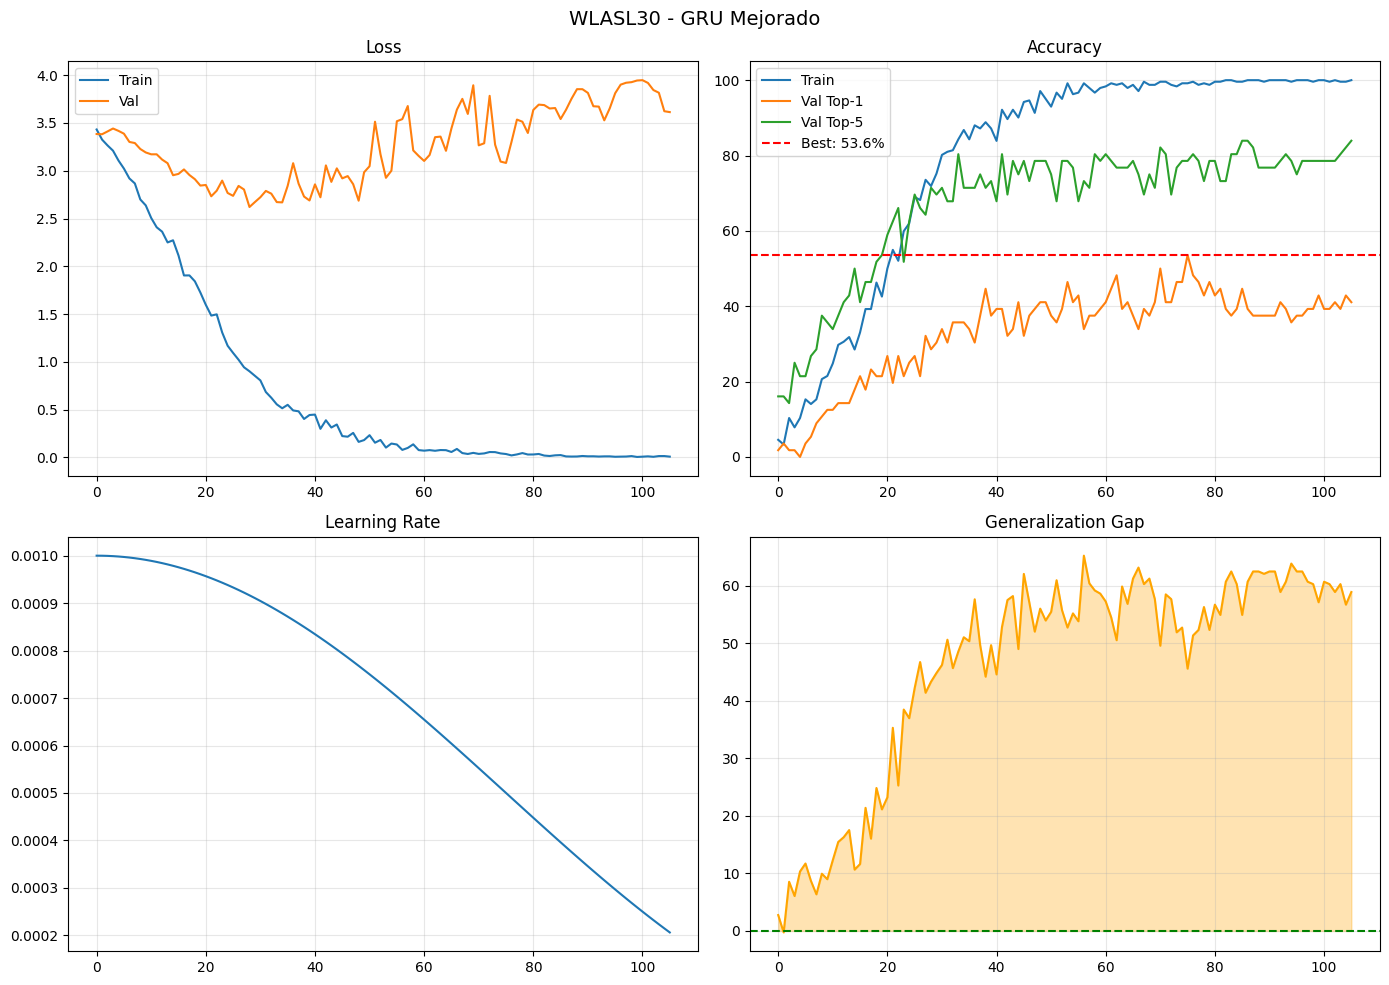

In [11]:
# ==========================================
# 11. CURVAS DE ENTRENAMIENTO
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(history['train_loss'], label='Train')
axes[0, 0].plot(history['val_loss'], label='Val')
axes[0, 0].set_title('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(history['train_acc'], label='Train')
axes[0, 1].plot(history['val_top1'], label='Val Top-1')
axes[0, 1].plot(history['val_top5'], label='Val Top-5')
axes[0, 1].axhline(y=best_val_top1, color='r', linestyle='--', label=f'Best: {best_val_top1:.1f}%')
axes[0, 1].set_title('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(history['lr'])
axes[1, 0].set_title('Learning Rate')
axes[1, 0].grid(True, alpha=0.3)

gap = np.array(history['train_acc']) - np.array(history['val_top1'])
axes[1, 1].plot(gap, color='orange')
axes[1, 1].fill_between(range(len(gap)), 0, gap, alpha=0.3, color='orange')
axes[1, 1].axhline(y=0, color='green', linestyle='--')
axes[1, 1].set_title('Generalization Gap')
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle(f'{DATASET.upper()} - {CONFIG["model_type"]} Mejorado', fontsize=14)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=150)
plt.show()

In [12]:
# ==========================================
# 12. EVALUACION EN TEST
# ==========================================

checkpoint = torch.load(OUTPUT_DIR / 'best_model.pt')
model.load_state_dict(checkpoint['model_state_dict'])
print(f"Modelo cargado: epoch {checkpoint['epoch']+1}")

test_metrics, test_preds, test_labels = evaluate(model, test_loader, criterion, device)

print("\n" + "="*50)
print("RESULTADOS EN TEST")
print("="*50)
print(f"Top-1 Accuracy: {test_metrics['top1_acc']:.1f}%")
print(f"Top-5 Accuracy: {test_metrics['top5_acc']:.1f}%")

Modelo cargado: epoch 76

RESULTADOS EN TEST
Top-1 Accuracy: 38.2%
Top-5 Accuracy: 76.5%


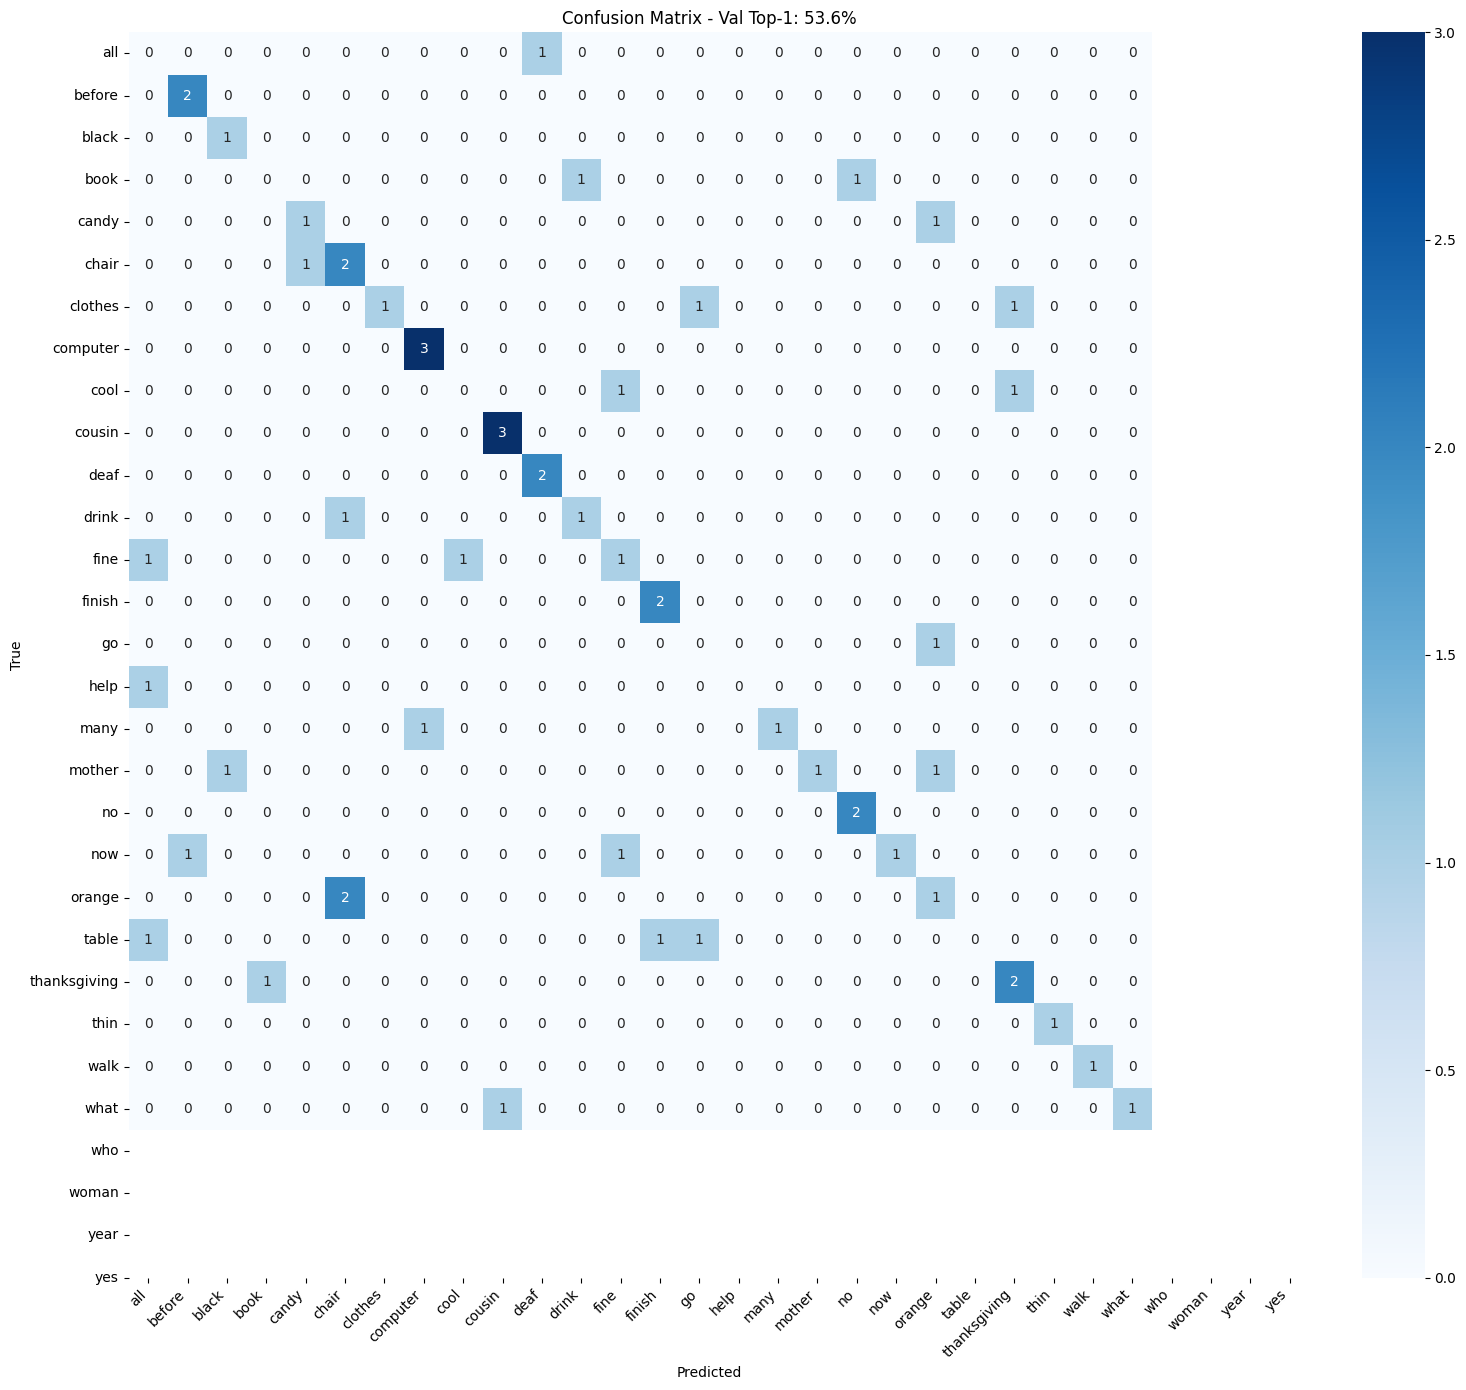

In [13]:
# ==========================================
# 13. MATRIZ DE CONFUSION
# ==========================================
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

val_metrics, val_preds, val_labels = evaluate(model, val_loader, criterion, device)

# Solo mostrar si hay menos de 40 clases (sino es muy grande)
if CONFIG['num_classes'] <= 40:
    cm = confusion_matrix(val_labels, val_preds)
    
    plt.figure(figsize=(16, 14))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=[idx_to_gloss[i] for i in range(CONFIG['num_classes'])],
                yticklabels=[idx_to_gloss[i] for i in range(CONFIG['num_classes'])])
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(f'Confusion Matrix - Val Top-1: {val_metrics["top1_acc"]:.1f}%')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=150)
    plt.show()
else:
    print(f"Matriz de confusion omitida (demasiadas clases: {CONFIG['num_classes']})")

In [14]:
# ==========================================
# 14. GUARDAR RESULTADOS
# ==========================================

results = {
    'dataset': DATASET,
    'config': CONFIG,
    'best_epoch': best_epoch,
    'best_val_top1': best_val_top1,
    'test_metrics': {k: float(v) for k, v in test_metrics.items()},
    'history': {k: [float(x) for x in v] for k, v in history.items()},
    'total_params': total_params
}

with open(OUTPUT_DIR / 'results.json', 'w') as f:
    json.dump(results, f, indent=2)

print(f"Resultados guardados en: {OUTPUT_DIR}")

Resultados guardados en: /home/fransando/Dev/tfg-sign-language-recognition/05_experiments/lstm_landmarks_wlasl30_gru_suave


In [15]:
# ==========================================
# 15. RESUMEN COMPARATIVO
# ==========================================

print("\n" + "="*70)
print("COMPARACION DE RESULTADOS")
print("="*70)
print("")
print("| Modelo                    | Val Top-1 | Test Top-1 | Test Top-5 | Params |")
print("|---------------------------|-----------|------------|------------|--------|")
print(f"| CNN+LSTM (imagenes)       | 16.8%     | 10.4%      | 27.8%      | 14.3M  |")
print(f"| LSTM (landmarks WLASL30)  | 37.5%     | 41.2%      | 67.6%      | 2.8M   |")
print(f"| {CONFIG['model_type']} Mejorado ({DATASET})    | {best_val_top1:.1f}%     | {test_metrics['top1_acc']:.1f}%      | {test_metrics['top5_acc']:.1f}%      | {total_params/1e6:.1f}M   |")
print("")
print(f"Objetivo del tutor: Top-1 60-70%")
print(f"Estado actual: {test_metrics['top1_acc']:.1f}%")

if test_metrics['top1_acc'] >= 60:
    print("\n*** OBJETIVO ALCANZADO! ***")
else:
    diff = 60 - test_metrics['top1_acc']
    print(f"\nFaltan {diff:.1f} puntos para el objetivo minimo")


COMPARACION DE RESULTADOS

| Modelo                    | Val Top-1 | Test Top-1 | Test Top-5 | Params |
|---------------------------|-----------|------------|------------|--------|
| CNN+LSTM (imagenes)       | 16.8%     | 10.4%      | 27.8%      | 14.3M  |
| LSTM (landmarks WLASL30)  | 37.5%     | 41.2%      | 67.6%      | 2.8M   |
| GRU Mejorado (wlasl30)    | 53.6%     | 38.2%      | 76.5%      | 2.1M   |

Objetivo del tutor: Top-1 60-70%
Estado actual: 38.2%

Faltan 21.8 puntos para el objetivo minimo


## Si llegas al 60%: Siguiente paso

Escala a WLASL100 con la misma configuracion (GRU + aug suave).

## Si NO llegas al 60%: Opciones

1. **Label smoothing**: `CrossEntropyLoss(label_smoothing=0.1)`
2. **Mas hidden_size**: Sube de 256 a 512
3. **Attention**: Añadir capa de atencion simple
4. **Ensemble**: Entrena 3 modelos, promedia predicciones
5. **Aumentar datos**: Usar WLASL completo y filtrar top 30 con mas videos